## Klasifikacija recenzija mobilnih aplikacija pomocu biblioteka **spaCy** i sklearn (Bag of Words i Decision Trees)

Zadatak klasifikacije u ovom notebook-u je razvrstavanje recenzija korisnika mobilnih aplikacija u tri kategorije, koriscenjem **Bag of Words (BoW)** pristupa za predstavljanje teksta i **algoritma stabla odlucivanja (Decision Tree – DT)** za klasifikaciju:
* funkcionalni zahtevi,
* nefunkcionalni zahtevi,
* ostalo.

Skup podataka koriscen u ovom notebooku potice iz  [Listening to the Crowd for the Release Planning of Mobile Apps](https://dl.acm.org/doi/abs/10.1109/TSE.2017.2759112).

In [42]:
import json
import pickle

# UCITAVANJE POTREBNIH BIBLIOTEKA

import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn import metrics

from sklearn.tree import DecisionTreeClassifier

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

import matplotlib.pyplot as plt
import seaborn as sb

import spacy

from IPython.display import display

from pathlib import Path

In [43]:
RAND_STATE = 1

#### UCITAVANJE PODATAKA

In [44]:
data = pd.read_csv(Path.cwd() / 'data' / 'mobile_apps_reviews.csv')

display(data.head(10))
data.info()

,id,app,version,rating,date,device,user,review,category
0,1,com.androtiyas.dragonvirtual,1.08,5,1387756426967,?,Alexis Gonzalez,cute!!!! the game is just to cute!!!! :3,OTHER
1,2,com.androtiyas.dragonvirtual,1.1,4,1390090741168,Galaxy Precedent,A Google User,? well its ok but not bad nor is it great,OTHER
2,3,com.androtiyas.dragonvirtual,?,1,1387746296815,Toshiba AT100,Reyna We,? have no idea how to feed dragon and boooorrr...,OTHER
3,4,com.androtiyas.dragonvirtual,1.06,2,1386518193950,?,mariah harris,when i play games it reboots about every third...,BUG
4,5,com.androtiyas.dragonvirtual,1.06,5,1386915595583,?,Wren Brown,love my dragon have fun! yahoooey! godbless,OTHER
5,6,com.androtiyas.dragonvirtual,1.11,5,1391710690867,?,Aribha Zahoor,hope this is a good game!!!! ?,OTHER
6,7,com.androtiyas.dragonvirtual,?,1,1396716326980,LG Optimus One,isaiah lawrence,sucks can't even play offline and everyone tak...,FEATURE
7,8,com.androtiyas.dragonvirtual,1.12,5,1397085800819,Samsung Galaxy Y,Charlotte Baynes,good that is so good,OTHER
8,9,com.androtiyas.dragonvirtual,1.1,5,1389305213694,HTC Wildfire S,A Google User,? realy good and fun,OTHER
9,10,com.androtiyas.dragonvirtual,1.11,5,1391957108087,?,Jennifer Bieber,999 this is the best,OTHER


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        3000 non-null   int64 
 1   app       3000 non-null   object
 2   version   3000 non-null   object
 3   rating    3000 non-null   int64 
 4   date      3000 non-null   int64 
 5   device    3000 non-null   object
 6   user      2991 non-null   object
 7   review    3000 non-null   object
 8   category  3000 non-null   object
dtypes: int64(3), object(6)
memory usage: 211.1+ KB


#### KREIRANJE IZLAZNE VARIJABLE

Koristicemo kolonu **_category_** za kreiranje izlazne varijable **_cls_**.

In [45]:
# pravimo novu kolonu cls sa 3 moguce vrednosti: OTHER, FUNCTIONAL (BUG, FEATURE) i NON-FUNCTIONAL (PERFORMANCE, USABILITY, ENERGY, SECURITY)

def category_to_cls(cat):
    if cat == 'OTHER': return cat
    return 'FUNCTIONAL' if cat in ['BUG', 'FEATURE'] else 'NON-FUNCTIONAL'


data['cls'] = data.category.apply(category_to_cls)

Provera balansiranosti dataseta

In [46]:
data.cls.value_counts(normalize=True)

# postoji class imbalance - klase nisu podjednako zastupljenje
# model moze da vara

cls
OTHER             0.501667
FUNCTIONAL        0.365667
NON-FUNCTIONAL    0.132667
Name: proportion, dtype: float64

Ako algoritam uopste ne analizira tekst recenzije, vec za svaku mogucu recenziju kaze da pripada klasi OTHER, on ce automatski imati tacnost (accuracy) od 50%.

Kreiranje varijable _review_len_

In [47]:
# duzina recenzija moze biti bitna - npr. duzi tekst uglavnom znaci da je u pitanju bag

data['review_len'] = data.review.apply(len)

In [48]:
# trenutni izgled dataseta:

data.head()

,id,app,version,rating,date,device,user,review,category,cls,review_len
0,1,com.androtiyas.dragonvirtual,1.08,5,1387756426967,?,Alexis Gonzalez,cute!!!! the game is just to cute!!!! :3,OTHER,OTHER,40
1,2,com.androtiyas.dragonvirtual,1.1,4,1390090741168,Galaxy Precedent,A Google User,? well its ok but not bad nor is it great,OTHER,OTHER,41
2,3,com.androtiyas.dragonvirtual,?,1,1387746296815,Toshiba AT100,Reyna We,? have no idea how to feed dragon and boooorrr...,OTHER,OTHER,60
3,4,com.androtiyas.dragonvirtual,1.06,2,1386518193950,?,mariah harris,when i play games it reboots about every third...,BUG,FUNCTIONAL,295
4,5,com.androtiyas.dragonvirtual,1.06,5,1386915595583,?,Wren Brown,love my dragon have fun! yahoooey! godbless,OTHER,OTHER,43


#### Provera znacajnosti prediktora

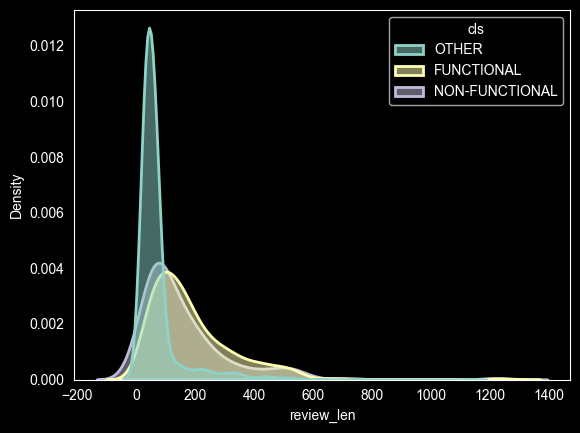

In [49]:
# review_len

plt.figure()
sb.kdeplot(data=data,
           x='review_len',
           hue='cls',
           fill=True,
           common_norm=False,
           # svaka kriva se normalizuje zasebno (povrsina = 1), pa se mogu porediti oblici raspodela bez obzira na to koliko je klasa velika
           alpha=0.5,
           linewidth=2)
plt.grid(False) # ja dodala jer je kod mene automatski grid
plt.show()

# izdvaja bar jednu klasu od ostale dve -> znacajan prediktor

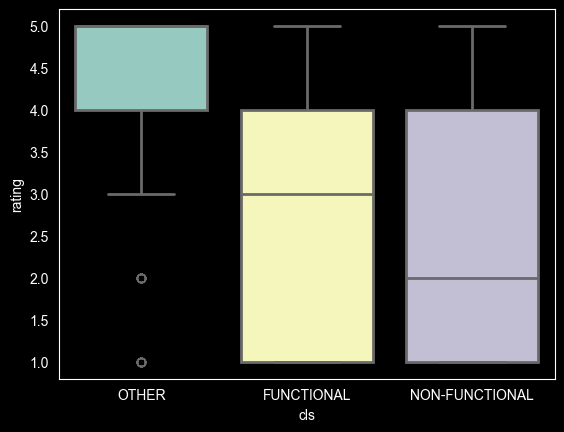

In [50]:
# rating

plt.figure()
# moze i ovde kdeplot
sb.boxplot(data=data,
           x='cls',
           y='rating',
           hue='cls', # kolona koja se koristi za bojenje - svaka ima svoju boju
           fill=True,
           linewidth=2,
           legend=False)
plt.grid(False)
plt.show()

# medijane po klasama se razlikuju (4,3,2) -> rating je takodje znacajan prediktor

In [51]:
# zadrzavamo tri prediktora (rating, review_len, review) i izlaznu varijablu (cls)

data_sub = data[['rating', 'review_len', 'review', 'cls']]

data_sub.head()

,rating,review_len,review,cls
0,5,40,cute!!!! the game is just to cute!!!! :3,OTHER
1,4,41,? well its ok but not bad nor is it great,OTHER
2,1,60,? have no idea how to feed dragon and boooorrr...,OTHER
3,2,295,when i play games it reboots about every third...,FUNCTIONAL
4,5,43,love my dragon have fun! yahoooey! godbless,OTHER


## PRETPROCESIRANJE TEKSTA (spacy)

In [52]:
# ucitavanje pipeline-a
nlp_pipe = spacy.load('en_core_web_sm')

In [53]:
def spacy_preprocessing(doc):
    # kreiranje tokena sa lingvistickim osobinama
    tokens = nlp_pipe(doc)
    # uklanjanje interpunkcija, praznina, brojeva i url
    tokens = [token for token in tokens
              if ((not token.is_punct) and (not token.is_space) and
                  (not token.like_num) and (not token.like_url))]
    # uklanjanje stop words, ali ostavljamo not - kljucno za analizu sentimenta (good != not good)
    tokens = [token for token in tokens
              if ((not token.is_stop) or (token.lemma_.lower() == 'not'))]

    # pretvaranje tokena u leme
    words = [token.lemma_ for token in tokens]

    # vracanje pretprocesuiranih reci
    return words

In [54]:
def create_count_vectorizer(ngrams=(1, 1), min_doc_freq=0.01, f_max=-1):
    vectoriser = CountVectorizer(
        tokenizer=spacy_preprocessing,  #umesto ugradjenog deljenja teksta, koristimo svoju funkciju
        token_pattern=None,  #kazemo da ne koristi regex
        ngram_range=ngrams,
        max_features=f_max if f_max > 0 else None,  # ogranicava recnik na n najcescih reci
        min_df=min_doc_freq  # rec ulazi u recnik samo ako se pojavljuje u najmanje 1% dokumenta
    )

    return vectoriser

# ngram_range=(1,1): n-gram je niz od n uzastopnih reci; (1,1) znaci samo pojedinacne reci (unigrami); (1,2) bi dodalo i parove ("not work"), cime se delimicno vraca kontekst, ali se recnik jako povecava

# max_features: ako je prosledjeni f_max veci od 0, zadrzace se samo top f_max najucestalijih reci
# posto je podrazumevano -1, uslov f_max > 0 nije ispunjen, pa se uzima None (recnik se ne ogranicava)

### KREIRANJE I TRENIRANJE PIPELINE-A ZA KLASIFIKACIJU TEKSTA

* PODELA NA TRAIN I TEST
* KREIRANJE VECTORISER-A I COLUMN TRANSFORMER-A
* KREIRANJE KLASIFIKATORA
* PIPELINE

#### DELJENJE PODATAKA NA TRAIN I TEST SKUP

In [55]:
X = data_sub.drop(columns='cls')
y = data_sub.cls.values

In [56]:
# faktorizacija izlazne promenljive na 0 1 2 (Decision Tree moze da radi i sa tekstualnim klasama, ali se ovde klase kodiraju u numericki oblik radi lakseg rada

y_encodings, y_levels = pd.factorize(y) # kodiranje tekstualnih ili kategorickih podataka u numericke vrednosti (celobrojne nizove)

# y_encodings - stvarne numericke oznake klasa: [0, 1, 2, 0, 2]
# y_levels - informacije o tome koji broj predstavlja koju originalnu klasu: ['other','functional', 'non-functional']

display(y_levels)
pd.Series(y_encodings).value_counts()

array(['OTHER', 'FUNCTIONAL', 'NON-FUNCTIONAL'], dtype=object)

0    1505
1    1097
2     398
Name: count, dtype: int64

In [57]:
X_train, X_test, y_train, y_test = train_test_split(
                                                    X,
                                                    y_encodings, # brojevi!!!
                                                    test_size=0.2,
                                                    random_state=RAND_STATE,
                                                    stratify=y_encodings
                                                    )

#### KREIRANJE VECTORISER-A I COLUMN TRANSFORMER-A

In [58]:
# pravimo instancu count vectoriser-a, koju smo gore definisali
count_vectorizer = create_count_vectorizer()

column_transformer = ColumnTransformer(
    [('word_counts', count_vectorizer, 'review')],
    remainder='passthrough' # sve preostale kolone, nenavedene
)

# [('ime_transformacije', transformator, 'kolona')]
# passthrough - sve kolone koje nismo posebno naveli samo prosledi dalje bez promene

#### KREIRANJE KLASIFIKATORA

In [59]:
# za klasifikaciju koristimo decision tree

classifier = DecisionTreeClassifier(random_state=RAND_STATE, min_impurity_decrease=0.001)

# min_impurity_decrease - kontrola grananja stabla

#### DEFINISANJE I TRENING PIPELINE-A

In [60]:
pipe = Pipeline([('vectorizer', column_transformer),
                 ('classifier', classifier)])
# saljemo naziv komponente i samu komponentu

pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('word_counts', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformer

### EVALUACIJA MODELA

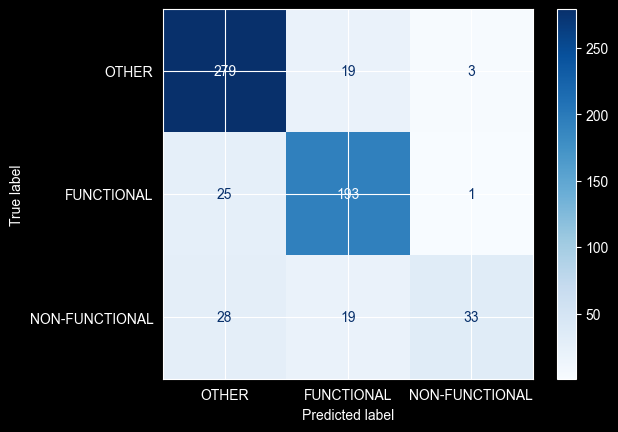

In [61]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay.from_estimator(
    pipe,
    X_test,
    y_test,
    display_labels=y_levels,
    cmap='Blues'
)

### Matrica konfuzije (Confusion Matrix)

Za detaljnu evaluaciju performansi ovog pipeline-a iskoriscena je matrica konfuzije dobijena pomocu funkcije `ConfusionMatrixDisplay.from_estimator`.

Prikazane vrednosti na **glavnoj dijagonali** oznacavaju tacna predvidjanja modela (True Positives), dok ostale celije pokazuju greske u klasifikaciji.

**Zakljucak:**
* **Klasa OTHER:** model najpreciznije prepoznaje ovu klasu. Uspesno je klasifikovao **279 recenzija**, dok je napravio minimalan broj gresaka (19 je pogresno svrstao u *Functional*, a samo 3 u *Non-Functional*).
* **Klasa FUNCTIONAL:** model pokazuje visoku uspesnost sa **193 tacno prepoznate recenzije**. Glavni izvor greske je mesanje sa klasom *OTHER* (25 recenzija), sto je ocekivano zbog kompleksnosti recnika i stilske slicnosti u tekstu recenzija.
* **Problem disbalansa klasa:** matrica potvrdjuje da model, uprkos izrazenom *class imbalance* problemu koji je uocen na pocetku, nije postao "lenj" baseline model (koji bi sve predvidjao kao *OTHER*).
Naprotiv, stablo odlucivanja uspesno pronalazi obrasce i visoko je selektivno za sve tri kategorije.

In [62]:
prediction = pipe.predict(X_test)

report= metrics.classification_report(y_true=y_test, y_pred=prediction)
print(report)

              precision    recall  f1-score   support

           0       0.84      0.93      0.88       301
           1       0.84      0.88      0.86       219
           2       0.89      0.41      0.56        80

    accuracy                           0.84       600
   macro avg       0.86      0.74      0.77       600
weighted avg       0.85      0.84      0.83       600



- **support** - ukupan broj pojavljivanja stvarnih uzoraka svake klase u y_true - u test skupu (npr. u test skupu ima tacno 301 recenzija koja je stvarno 'OTHER')


- **macro avg** - prosek rezultata po klasama, pri cemu svaka klasa ima jednaku tezinu, nezavisno od broja njenih uzoraka i zbog toga los rezultat na manjinskoj ili tezoj klasi znacajno utice na konacnu vrednost proseka


- **weighted avg** - racuna prosek tako sto uzima u obzir broj primeraka (support) svake klase; klase koje imaju vise uzoraka u data setu imaju i veci uticaj na krajnji rezultat; koristan je kada nam je bitna ukupna tacnost na celom (nebalansiranom) skupu

#### BALANCED ACCURACY

S obzirom da smo vec utvrdili da dataset nije balansiran (podsetimo se da je vise od 50% rezencija klase OTHER), racunacemo i **balanced accuracy**.

Balanced accuracy se racuna kao zbir accuracy po klasama podeljen sa ukupnim brojem testnih uzoraka.

Koristimo ga kada zelimo da obezbedimo da model ne postize visok ukupni rezultat, a da pri tome lose klasifikuje manjinsku klasu (realno prikazuje uspeh ako jedna klasa ima znatno manje primeraka od druge).

In [63]:
display(f"Accuracy: {metrics.accuracy_score(y_test, prediction):0.4f}")
display(f"Balanced accuracy: {metrics.balanced_accuracy_score(y_test, prediction, adjusted=True):0.4f}")

'Accuracy: 0.8417'

'Balanced accuracy: 0.6103'

- **slucajni model** - model koji nema nikakvo znanje i samo nasumicno bira klasu


- `adjusted=True` - postavlja njegov rezultat kao 0 kako bi se lakse procenilo koliko je nas model bolji od slucajnog pogadjanja


- sve sto model uradi iznad nule je njegovo stvarno znanje, dok bi negativan rezultat znacio da radi gore od slucajnog pogadjanja

## ZADACI
### Zadatak 1
Izmeniti funkciju spacy_preprocessing tako da iz zadatog teksta (ulazni argument) budu zadrzane samo reci koje su imenice, pridevi i glagoli.

Kreirati i evaluirati model dobijen ovim oblikom selekcije atributa.

In [64]:
def spacy_preprocessing2(doc):

    # kreiranje tokena sa lingvistckim osobinama
    tokens = nlp_pipe(doc)

    # uklanjanje interpunkcija, praznina, brojeva i url
    tokens = [token for token in tokens
              if ((not token.is_punct) and (not token.is_space)
                  and (not token.like_num) and (not token.like_url))]

    # DODATO: zadrzavamo imenice (navodimo i vlastite posebno), prideve i glagole + 'not'
    tokens = [token for token in tokens
              if ((token.pos_ in ['NOUN','PROPN','VERB','ADJ'])
                  or (token.lemma_.lower() == 'not'))]

    # uklanjanje stopwords (izuzetak not)
    tokens = [token for token in tokens
              if ((not token.is_stop) or (token.lemma_.lower() == 'not'))]

    # pretvaranje tokena u leme
    words = [token.lemma_.lower() for token in tokens]

    #vracanje pretprocesuiranih reci
    return words

In [65]:
def create_count_vectorizer2(ngrams = (1,1), min_doc_freq = 0.01, f_max = -1):

    vectorizer = CountVectorizer(
        tokenizer=spacy_preprocessing2,
        token_pattern=None,
        ngram_range=ngrams,
        max_features=f_max if f_max>0 else None,
        min_df=min_doc_freq
    )

    return vectorizer

In [66]:
count_vectorizer2 = create_count_vectorizer2()

column_transformer2 = ColumnTransformer(
    [('bow', count_vectorizer2, 'review')],
     remainder = 'passthrough'
)

In [67]:
pipe2 = Pipeline(
    [('preprocessor', column_transformer2),
     ('classifier', classifier)]
)
pipe2.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('bow', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers cont

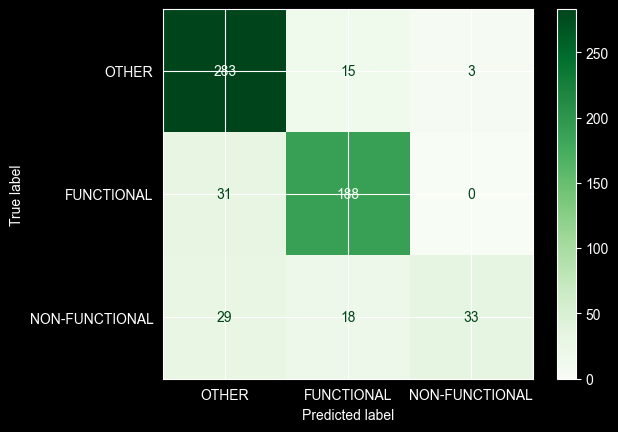

In [68]:
disp = ConfusionMatrixDisplay.from_estimator(
    pipe2,
    X_test,
    y_test,
    display_labels=y_levels,
    cmap='Greens'
)

In [69]:
prediction_2 = pipe2.predict(X_test)

report_2 = metrics.classification_report(y_true=y_test, y_pred=prediction_2)
print(report_2)

              precision    recall  f1-score   support

           0       0.83      0.94      0.88       301
           1       0.85      0.86      0.85       219
           2       0.92      0.41      0.57        80

    accuracy                           0.84       600
   macro avg       0.86      0.74      0.77       600
weighted avg       0.85      0.84      0.83       600



In [70]:
display(f'Accuracy: {metrics.accuracy_score(y_test, prediction_2):0.4f}')
display(f'Balanced accuracy: {metrics.balanced_accuracy_score(y_test, prediction_2, adjusted=True):0.4f}')

'Accuracy: 0.8400'

'Balanced accuracy: 0.6056'

### Zadatak 2
Koristeci spaCy, kreirati nove atribute koji predstavljaju:

* Broj imenica
* Broj glagola
* Broj imenovanih entiteta
* Broj znakova interpunkcije
Ispitati koliko su ovi atributi potencijalno znacajni za predvidjanje izlazne varijable.

In [71]:
def create_spacy_features(doc):

    tokens = nlp_pipe(doc)

    num_nouns = sum(token.pos_ in ['NOUN','PROPN'] for token in tokens)
    num_verbs = sum(token.pos_ == 'VERB' for token in tokens)
    num_entities = len(tokens.ents)
    num_punct = sum(token.is_punct for token in tokens)

    return {
        'num_nouns':num_nouns,
        'num_verbs':num_verbs,
        'num_entities':num_entities,
        'num_punct':num_punct
    }

In [72]:
features = data_sub.review.apply(create_spacy_features)
features.head()

0    {'num_nouns': 1, 'num_verbs': 1, 'num_entities...
1    {'num_nouns': 0, 'num_verbs': 0, 'num_entities...
2    {'num_nouns': 3, 'num_verbs': 2, 'num_entities...
3    {'num_nouns': 11, 'num_verbs': 12, 'num_entiti...
4    {'num_nouns': 4, 'num_verbs': 2, 'num_entities...
Name: review, dtype: object

In [73]:
features_df = pd.DataFrame(data=features.tolist(), index=data_sub.index)
features_df.head()

,num_nouns,num_verbs,num_entities,num_punct
0,1,1,0,8
1,0,0,0,1
2,3,2,0,1
3,11,12,1,0
4,4,2,1,2


In [74]:
data_sub = pd.concat([data_sub,features_df],axis=1)
data_sub.head()

,rating,review_len,review,cls,num_nouns,num_verbs,num_entities,num_punct
0,5,40,cute!!!! the game is just to cute!!!! :3,OTHER,1,1,0,8
1,4,41,? well its ok but not bad nor is it great,OTHER,0,0,0,1
2,1,60,? have no idea how to feed dragon and boooorrr...,OTHER,3,2,0,1
3,2,295,when i play games it reboots about every third...,FUNCTIONAL,11,12,1,0
4,5,43,love my dragon have fun! yahoooey! godbless,OTHER,4,2,1,2


In [77]:
def draw_kdeplot(v):
    plt.figure()
    sb.kdeplot(
        data=data_sub,
        x=v,
        hue='cls',
        fill=True,
        common_norm=False,
        alpha=0.5,
        linewidth=2
    )
    plt.grid(False)
    plt.show()

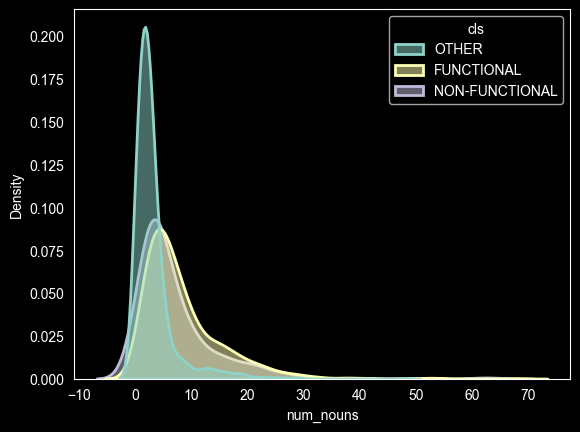

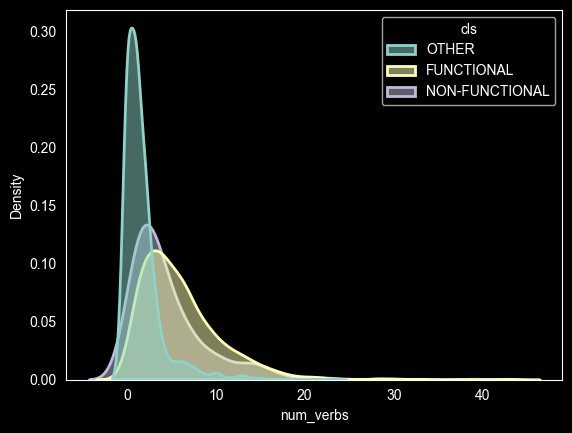

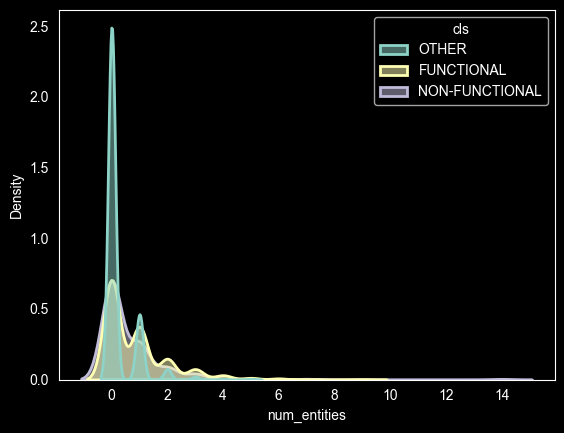

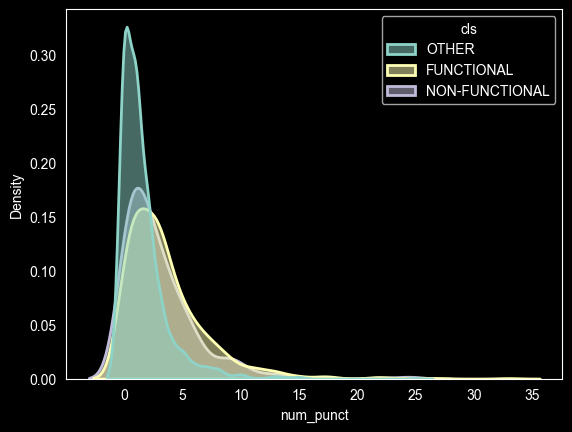

In [78]:
for col in features_df.columns:
    draw_kdeplot(col)

Kod sve 4 varijable, raspodele se dosta preklapaju, ali kod atributa **`num_nouns`** i **`num_verbs`**, klasa OTHER se malo vise izdvaja u odnosu na preostale dve, pa zakljucujemo da su oni dobri prediktori.

### Zadatak 3
**Istraziti argumente CountVectoriser konstruktora** (tj. hiperparametre koje je moguce podesavati) i njihov **efekat na performanse klasifikatora**:

Utvrditi (npr. pretragom Interneta) **koji su to argumenti CountVectoriser-a koji se najcesce podesavaju** i u **kojim opsezima** se njihove vrednosti tipicno traze.

Uvrstiti neki od identifikovanih znacajnih argumenata u **postupak finog podesavanja (fine-tuning) pipeline-a**, radjen na casu predavanja, i ispitati kako se to odrazava na performanse klasifikacije.

## Istrazivanje hiperparametara CountVectorizer-a
**`CountVectorizer`** je komponenta koja tekstualne dokumente pretvara u numericku reprezentaciju zasnovanu na broju pojavljivanja reci, odnosno n-grama. Njegovim hiperparametrima moze se uticati na izbor atributa koji ce biti prosledjeni klasifikatoru.

Kao najznacajniji hiperparametri za podesavanje izdvojeni su min_df, max_df, max_features i ngram_range.

**`min_df`** odredjuje minimalnu ucestalost atributa u dokumentima. Moze biti zadat kao apsolutni broj dokumenata ili kao udeo dokumenata. Uobicajeno je ispitivati manje vrednosti, npr. `1, 2, 5 i 10`, odnosno odgovarajuce male procente kod vecih skupova podataka. Njegovim povecanjem uklanjaju se veoma retki atributi.

**`max_df`** odredjuje maksimalnu ucestalost atributa. Vrednost moze biti apsolutni broj ili udeo dokumenata. Cesto se ispituju vrednosti iz opsega priblizno `0.7–1.0`, cime se mogu ukloniti atributi koji se pojavljuju u velikom broju dokumenata i imaju malu diskriminativnu vrednost.

**`max_features`** odredjuje maksimalan broj atributa koji će biti zadrzan. Tipicne eksperimentalne vrednosti zavise od velicine skupa podataka, a mogu se ispitivati vrednosti poput `1000, 5000, 10000 i 20000`. Ako se ne postavi, koristi se kompletan pronadjeni recnik.

**`ngram_range`** odredjuje koje n-grame treba koristiti kao atribute. Podrazumevana vrednost `(1,1)` koristi samo unigramove, dok `(1,2)` koristi i unigramove i bigramove, a `(1,3)` unigramove, bigramove i trigramove. Ovaj parametar je narocito znacajan kod klasifikacije teksta jer kombinacije vise uzastopnih reci mogu sadrzati informaciju koja nije prisutna u pojedinacnim recima.

Pored navedenih, mogu se podesavati i `binary`, `stop_words`, `analyzer`, `token_pattern` i drugi argumenti.

### Unapredjenje klasifikatora pomocu hiperparametara
#### * dopuna gradiva iz prve nedelje na drugom predavanju
#### * koristimo prvi pipeline
Sada cemo pokusati da poboljsamo performanse klasifikatora tako sto cemo **_promeniti nacin transformacije teksta_** i **_slozenost stabla odlucivanja_**.

Cesto korisceni hiperparametri za transformaciju teksta ukljucuju:

* `min_df` – minimalna ucestalost pojavljivanja reci u dokumentima.

* `ngram_range` – opseg n-grama koji se koriste kao atributi (features).

Mozemo da isprobamo oba hiperparametra, ali bi to zahtevalo dosta vremena za izvrsavanje. Zato cemo se fokusirati na jedan i odrediti njegovu optimalnu vrednost pomocu unakrsne validacije (Cross-Validation), koristeci klasu **`GridSearchCV`**.

**_Napomena:_** Nazivima hiperparametara mora prethoditi naziv odgovarajuce komponente u pipeline-u (transformatora ili estimatora). U ovom slucaju, nazivi relevantnih komponenti su `vectorizer` i `classifier`.

Medjutim, posto **`vectorizer`** **nije jedan transformator**, vec moze da sadrzi vise transformatora (po jedan za svaku kolonu), **potrebno je da navedemo naziv konkretnog transformatora** cije parametre zelimo da optimizujemo. U ovom slucaju, to je **`word_counts`**.

Zato **nazivu hiperparametra za transformaciju teksta** moramo da dodamo **prefiks** **`vectorizer__word_counts__`**.

In [80]:
%%time
# meri koliko je sekundi/minuta racunaru trebalo da izvrsi celu ovu celiju

param_grid = {
    'vectorizer__word_counts__min_df':[0.005, 0.01, 0.025], # 3 vrednosti za tekst
    'classifier__min_impurity_decrease': [0.001, 0.005, 0.01] # 3 vrednosti za stablo
} # => 9 kombinacija koje racunar mora da isproba
grid_search = GridSearchCV(pipe,
                           param_grid=param_grid,
                           scoring='f1_macro',
                           verbose=2)

# uzima moj pipeline i za svaku od 9 kombinacija radi kros validaciju
# podrazumevano podesen na 5 krugova (folds) => istrenirao i testirao model 45 puta

# scoring='f1_macro': bira najbolju kombinaciju na osnovu F1-skora - harmonijska sredina preciznosti i odziva
# macro - daje svakoj klasi jednaku vaznost

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 9 candidates, totalling 45 fits
[CV] END classifier__min_impurity_decrease=0.001, vectorizer__word_counts__min_df=0.005; total time=  28.3s
[CV] END classifier__min_impurity_decrease=0.001, vectorizer__word_counts__min_df=0.005; total time=  23.7s
[CV] END classifier__min_impurity_decrease=0.001, vectorizer__word_counts__min_df=0.005; total time=  19.9s
[CV] END classifier__min_impurity_decrease=0.001, vectorizer__word_counts__min_df=0.005; total time=  20.0s
[CV] END classifier__min_impurity_decrease=0.001, vectorizer__word_counts__min_df=0.005; total time=  22.4s
[CV] END classifier__min_impurity_decrease=0.001, vectorizer__word_counts__min_df=0.01; total time=  20.2s
[CV] END classifier__min_impurity_decrease=0.001, vectorizer__word_counts__min_df=0.01; total time=  19.9s
[CV] END classifier__min_impurity_decrease=0.001, vectorizer__word_counts__min_df=0.01; total time=  24.5s
[CV] END classifier__min_impurity_decrease=0.001, vectorizer__word_counts__min_

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__min_impurity_decrease': [0.001, 0.005, ...], 'vectorizer__word_counts__min_df': [0.005, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and paramete

In [ ]:
display('Najbolji hiperparametri: ', grid_search.best_params_)
display('Najbolji score: ', grid_search.best_score_)

In [ ]:
# ponovno pokretanje pipeline-a sa optimalnim vrednostima hiperparametara

best_min_df = grid_search.best_params_['vectorizer__word_counts__min_df']
best_min_impurity_decrease = grid_search.best_params_['classifier__min_impurity_decrease']

pipe.set_params(vectorizer__word_counts__min_df=best_min_df,
                classifier__min_impurity_decrease=best_min_impurity_decrease)

pipe.fit(X_train, y_train)

In [ ]:
prediction_3 = pipe.predict(X_test)

report_3 = metrics.classification_report(y_true=y_test, y_pred=prediction_3)
print(report_3)

In [ ]:
display(f"Accuracy: {metrics.accuracy_score(y_test, prediction_3):0.4f}")
display(f"Balanced accuracy: {metrics.balanced_accuracy_score(y_test, prediction_3, adjusted=True):0.4f}")

### CUVANJE NAJBOLJEG MODELA I NJEGOVIH REZULTATA

In [ ]:
results_dir = Path.cwd() / 'results'
if not results_dir.exists():
    results_dir.mkdir()

with open(results_dir / 'BoW_best_model.pkl', 'wb') as fobj:
    pickle.dump(pipe, fobj)

with open(results_dir / 'BoW_best_model_scores.json', 'w') as fobj:
    model_scores = metrics.classification_report(y_true=y_test, y_pred=prediction_3, output_dict=True)
    json.dump(model_scores, fobj, indent=4)

`pickle.dump(pipe, fobj)` - snima ceo moj istrenirani model u fajl BoW_best_model.pkl.

To znaci da sutra mogu samo da ucitam ovaj fajl i odmah predvidjam tekst, bez ponovnog cekanja od po 15 minuta na Grid Search.

`output_dict=True` - vraca recnik umesto stringa.

`json.dump(..., indent=4)` - pretvara tabelu sa rezultatima u citljiv tekstualni fajl BoW_best_model_scores.json.
Parametar indent=4 sluzi da fajl bude lepo formatiran (sa uvucenim redovima).